# Độ nhạy và công bằng

Fixed và retarget có ý nghĩa khác nhau. Nhóm mẫu nhỏ không đủ cho kết luận chắc chắn.

Chạy `python -m telco_retention run-all` trước. Notebook sử dụng artifacts và logic của package, không có mô hình thứ hai độc lập.

In [1]:
from telco_retention.common import ROOT, latest_run, read_json
import pandas as pd
from IPython.display import display, Image
run = latest_run()
print('Run:', run.name)

Run: 20261003T133607624165Z-88be4b93


In [2]:
display(pd.read_csv(run / 'sensitivity.csv'))
display(pd.read_csv(run / 'budget_curve.csv'))

,axis,parameter,cost_multiplier,mode,turnover,budget_feasible,selected_count,cost,remaining_budget,expected_saved,expected_retained_value,expected_net_value,roi,precision_contacted,label_based_simulated_net,high_risk_high_value_coverage,scenario_id
0,cost_save_rate,0.05,0.50,fixed,0.000000,True,140,1680.0,1400.0,4.332539,1484.803818,-195.196182,-0.116188,0.607143,-232.84725,0.980392,NaN
1,cost_save_rate,0.05,0.50,retarget,0.821429,True,25,300.0,2780.0,0.764288,328.406882,28.406882,0.094690,0.560000,0.72375,0.392157,1a32b7503f51
2,cost_save_rate,0.05,0.75,fixed,0.000000,True,140,2380.0,700.0,4.332539,1484.803818,-895.196182,-0.376133,0.607143,-932.84725,0.980392,NaN
3,cost_save_rate,0.05,0.75,retarget,1.000000,True,0,0.0,3080.0,0.000000,0.000000,0.000000,NaN,NaN,0.00000,0.000000,3dbb2c70ce81
4,cost_save_rate,0.05,1.00,fixed,0.000000,True,140,3080.0,0.0,4.332539,1484.803818,-1595.196182,-0.517921,0.607143,-1632.84725,0.980392,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,horizon,12.00,1.00,retarget,0.000000,True,140,3080.0,0.0,17.330156,5939.215272,2859.215272,0.928317,0.607143,2708.61100,0.980392,765d0287b0f6
70,horizon,18.00,1.00,fixed,0.000000,True,140,3080.0,0.0,17.330156,8908.822908,5828.822908,1.892475,0.607143,5602.91650,0.727891,NaN
71,horizon,18.00,1.00,retarget,0.000000,True,140,3080.0,0.0,17.330156,8908.822908,5828.822908,1.892475,0.607143,5602.91650,0.727891,7338cc204328
72,uniform_tenure,1.00,1.00,fixed,0.000000,True,140,3080.0,0.0,17.330156,5939.336282,2859.336282,0.928356,0.607143,2748.40000,0.909091,NaN


,budget,strategy,selected_count,cost,remaining_budget,expected_saved,expected_retained_value,expected_net_value,roi,precision_contacted,label_based_simulated_net,high_risk_high_value_coverage,scenario_id,solver_status
0,0.0,risk,0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,0.000,0.000000,8b1e8443c4db,NaN
1,0.0,value,0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,0.000,0.000000,34e64bfafef2,NaN
2,0.0,ev,0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,0.000,0.000000,44f36154bf10,NaN
3,0.0,multi_offer,0,0.0,0.0,0.000000,0.000000,0.000000,NaN,NaN,0.000,0.000000,4207db719a73,optimal
4,2958.9,risk,134,2948.0,10.9,19.954476,4593.386859,1645.386859,0.558137,0.716418,1421.608,0.019608,951ed4398a59,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,56219.1,multi_offer,421,10742.0,45477.1,51.810110,15688.732697,4946.732697,0.460504,0.541568,4786.969,1.000000,420d6009d862,optimal
80,59178.0,risk,1409,30998.0,28180.0,75.646339,19529.553402,-11468.446598,-0.369974,0.265436,-11246.240,1.000000,be7c5634fd42,NaN
81,59178.0,value,1409,30998.0,28180.0,75.646339,19529.553402,-11468.446598,-0.369974,0.265436,-11246.240,1.000000,6a596d083e43,NaN
82,59178.0,ev,421,9262.0,49916.0,47.220560,13963.589327,4701.589327,0.507621,0.541568,4500.854,1.000000,629517da84bb,NaN


In [3]:
display(pd.read_csv(run / 'fairness.csv'))

,strategy,attribute,group,n,small_sample,selection_rate,mean_probability,observed_churn,calibration_gap,average_precision,roc_auc,brier,log_loss,precision,recall,f1
0,ev,gender,Female,714,False,0.110644,0.278731,0.289916,-0.011185,0.601590,0.816930,0.154859,0.463844,0.560606,0.714976,0.628450
1,ev,gender,Male,695,False,0.087770,0.257867,0.240288,0.017579,0.644136,0.845411,0.128714,0.398638,0.524664,0.700599,0.600000
2,ev,SeniorCitizen,0,1170,False,0.070085,0.241280,0.232479,0.008801,0.608322,0.841560,0.128899,0.397392,0.534884,0.676471,0.597403
3,ev,SeniorCitizen,1,239,False,0.242678,0.401397,0.426778,-0.025381,0.648661,0.736224,0.205911,0.599539,0.566434,0.794118,0.661224
4,ev,tenure_segment,developing,204,False,0.122549,0.297771,0.274510,0.023261,0.525688,0.785232,0.161071,0.475368,0.488636,0.767857,0.597222
5,ev,tenure_segment,loyal,774,False,0.089147,0.145750,0.152455,-0.006705,0.433146,0.822111,0.104123,0.334944,0.443548,0.466102,0.454545
6,ev,tenure_segment,new,431,False,0.106729,0.474886,0.464037,0.010849,0.707469,0.753550,0.200871,0.584725,0.607273,0.835000,0.703158
7,segment_policy,gender,Female,714,False,0.110644,0.278731,0.289916,-0.011185,0.601590,0.816930,0.154859,0.463844,0.560606,0.714976,0.628450
8,segment_policy,gender,Male,695,False,0.087770,0.257867,0.240288,0.017579,0.644136,0.845411,0.128714,0.398638,0.524664,0.700599,0.600000
9,segment_policy,SeniorCitizen,0,1170,False,0.070085,0.241280,0.232479,0.008801,0.608322,0.841560,0.128899,0.397392,0.534884,0.676471,0.597403


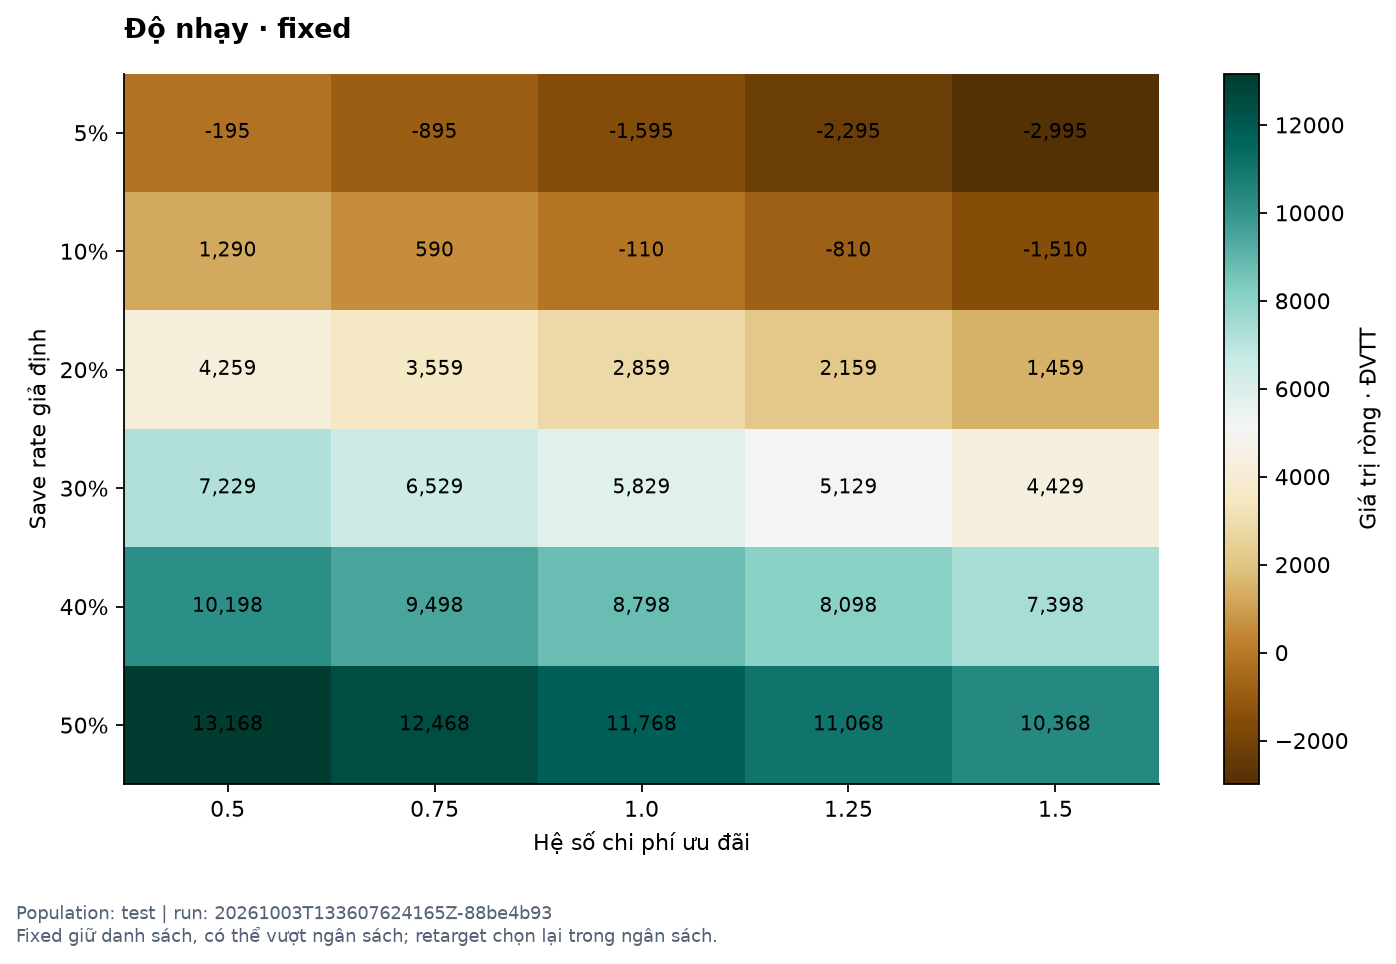

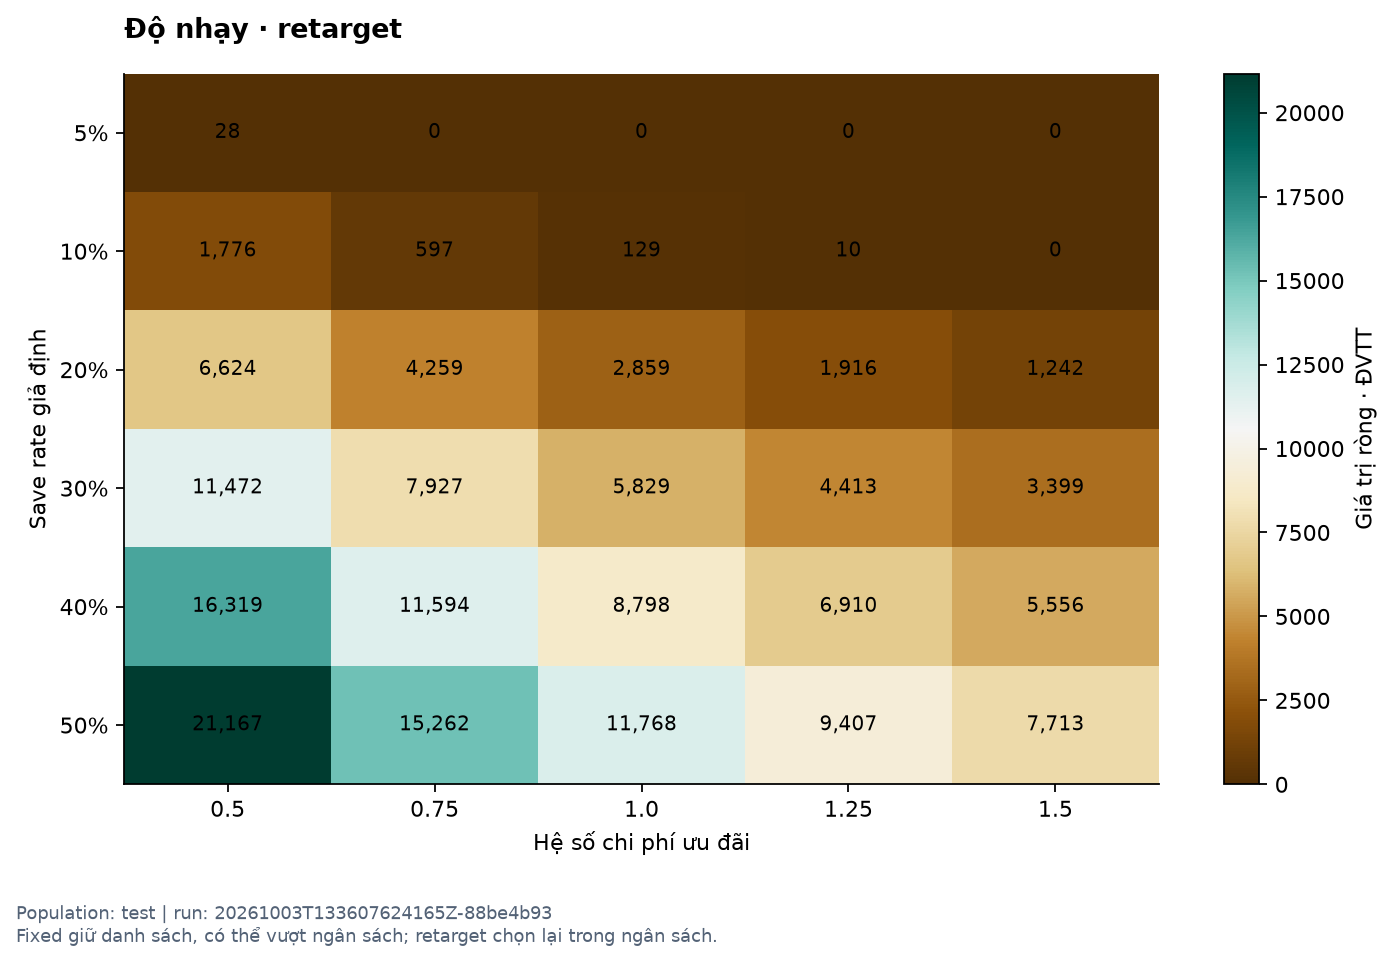

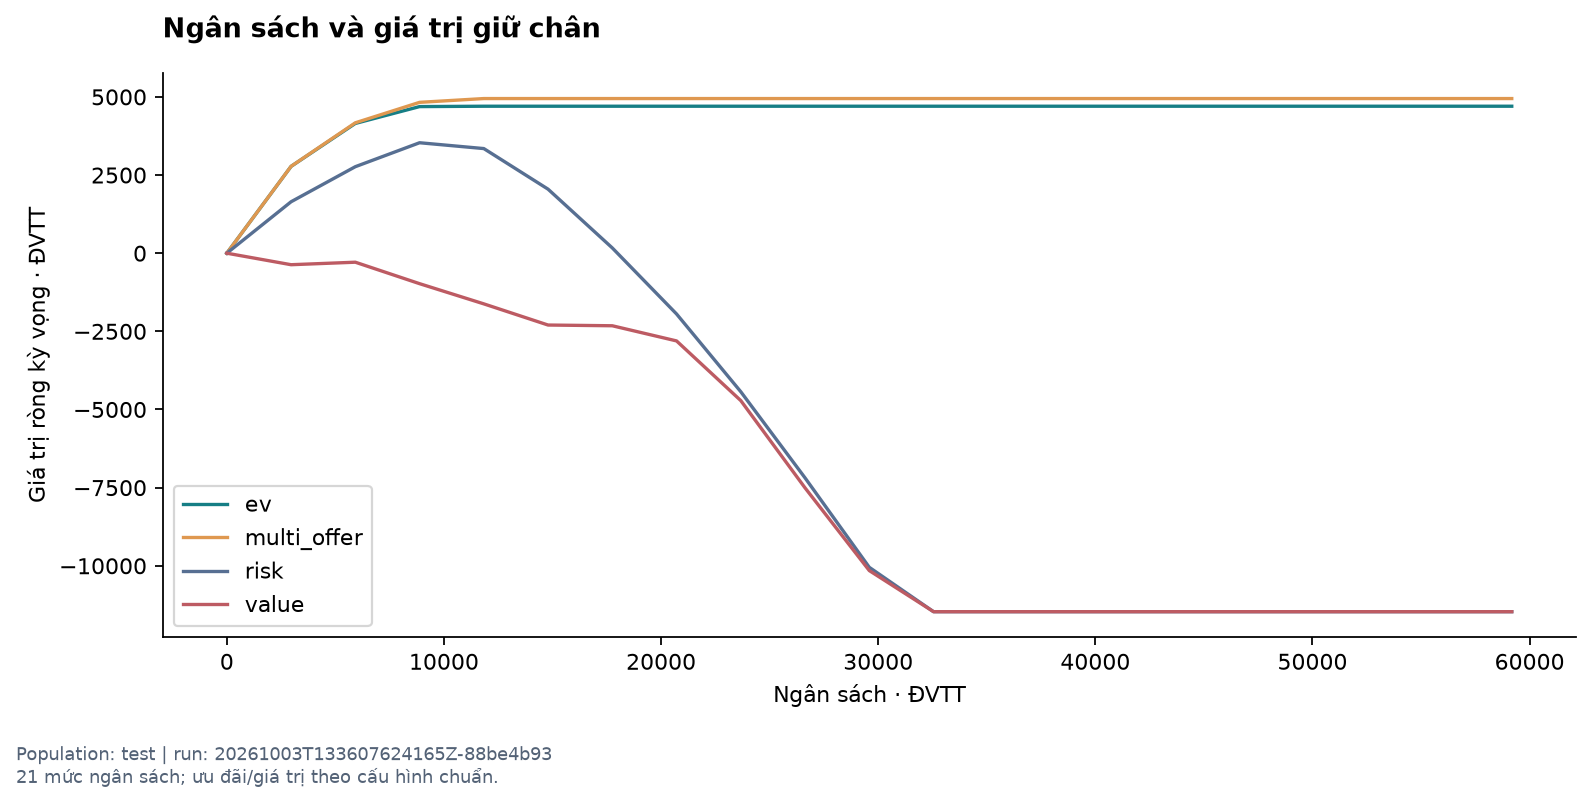

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/sensitivity_fixed.png')))
display(Image(filename=str(ROOT / 'reports/figures/sensitivity_retarget.png')))
display(Image(filename=str(ROOT / 'reports/figures/budget_curve.png')))